<a href="https://colab.research.google.com/github/RUNjgRUN/learn-git-2025/blob/main/Food_survey_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Food Survey Data Analysis**

In [ ]:
# Step 1: Import libiaries and loading the data

import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Step 2: Uploading the file from computer

from google.colab import files
uploaded = files.upload()

# then reading the file
food = pd.read_csv("foods.csv")

Saving foods.csv to foods (1).csv


In [ ]:
# Step 3: checking the file

food.head()

,First Name,Gender,City,Frequency,Item,Spend
0,Wanda,Female,Stamford,Weekly,Burger,15.66
1,Eric,Male,Stamford,Daily,Chalupa,10.56
2,Charles,Male,New York,Never,Sushi,42.14
3,Anna,Female,Philadelphia,Once,Ice Cream,11.01
4,Deborah,Female,Philadelphia,Daily,Chalupa,23.49


In [ ]:
# Step 4: explore the data file

food.columns

Index(['First Name', 'Gender', 'City', 'Frequency', 'Item', 'Spend'], dtype='object')

In [ ]:
food.shape

(1000, 6)

In [ ]:
food.dtypes

,0
First Name,object
Gender,object
City,object
Frequency,object
Item,object
Spend,float64


In [ ]:
# checking for missing values
food.isnull().sum()

,0
First Name,0
Gender,0
City,0
Frequency,0
Item,0
Spend,0


In [ ]:
# statistical summary for spend column

food["Spend"].describe()

,Spend
count,1000.000000
mean,50.069370
std,27.728471
min,1.020000
25%,27.380000
50%,48.825000
75%,73.092500
max,99.870000


In [ ]:
# checking unique values for categorical columns

food["City"].unique()

array(['Stamford', 'New York', 'Philadelphia'], dtype=object)

In [ ]:
food["City"].nunique()

3

In [ ]:
food["Frequency"].unique()

array(['Weekly', 'Daily', 'Never', 'Once', 'Monthly', 'Seldom', 'Often',
       'Yearly'], dtype=object)

In [ ]:
food["Gender"].unique()

array(['Female', 'Male'], dtype=object)

In [ ]:
# Step 5: Cleaning and data type formatting

In [ ]:
# Step 6: Data Analysis(Filtering data)

# High spending with over 90

food[food["Spend"] > 90]

,First Name,Gender,City,Frequency,Item,Spend
5,Charles,Male,Stamford,Monthly,Sushi,93.03
15,Paul,Male,Philadelphia,Often,Ice Cream,97.67
18,Bruce,Male,Stamford,Often,Ice Cream,99.17
25,Carol,Female,Philadelphia,Daily,Burger,90.66
43,George,Male,Philadelphia,Often,Donut,93.12
...,...,...,...,...,...,...
976,Jesse,Male,Philadelphia,Never,Ice Cream,95.69
986,Ann,Female,Stamford,Yearly,Chalupa,92.16
990,Pamela,Female,New York,Never,Burger,97.89
992,Raymond,Male,New York,Never,Burger,90.32


In [ ]:
# list of female customer from NY city

food[(food["Gender"] == "Female") &
(food["City"] == "New York")]

,First Name,Gender,City,Frequency,Item,Spend
13,Lori,Female,New York,Daily,Burrito,34.92
17,Frances,Female,New York,Weekly,Chalupa,3.54
21,Rose,Female,New York,Weekly,Sushi,40.76
23,Phyllis,Female,New York,Often,Donut,28.78
27,Stephanie,Female,New York,Weekly,Ice Cream,77.70
...,...,...,...,...,...,...
962,Brenda,Female,New York,Monthly,Burrito,16.36
983,Amy,Female,New York,Daily,Donut,20.78
990,Pamela,Female,New York,Never,Burger,97.89
995,Donna,Female,New York,Monthly,Sushi,83.53


In [ ]:
food[food["Item"] == "Sushi"]

,First Name,Gender,City,Frequency,Item,Spend
2,Charles,Male,New York,Never,Sushi,42.14
5,Charles,Male,Stamford,Monthly,Sushi,93.03
11,Rachel,Female,Philadelphia,Seldom,Sushi,71.68
21,Rose,Female,New York,Weekly,Sushi,40.76
26,Dennis,Male,Philadelphia,Never,Sushi,12.38
...,...,...,...,...,...,...
970,Rachel,Female,Philadelphia,Seldom,Sushi,11.68
975,Carol,Female,Stamford,Once,Sushi,8.38
977,John,Male,New York,Yearly,Sushi,70.78
995,Donna,Female,New York,Monthly,Sushi,83.53


In [ ]:
# filtering Stamford high spenders

food[(food["City"] == "Stamford") & (food["Spend"] > 90)]

,First Name,Gender,City,Frequency,Item,Spend
5,Charles,Male,Stamford,Monthly,Sushi,93.03
18,Bruce,Male,Stamford,Often,Ice Cream,99.17
50,Anthony,Male,Stamford,Weekly,Sushi,96.97
87,Julie,Female,Stamford,Often,Chalupa,93.96
104,Stephen,Male,Stamford,Yearly,Chalupa,96.90
127,Alice,Female,Stamford,Seldom,Burrito,94.99
153,Joshua,Male,Stamford,Monthly,Chalupa,93.25
160,Theresa,Female,Stamford,Weekly,Donut,91.75
186,Teresa,Female,Stamford,Monthly,Chalupa,93.08
190,Kenneth,Male,Stamford,Seldom,Sushi,98.48


In [ ]:
# Group By

# average spending by group
food.groupby("City")["Spend"].mean().round(2)

,Spend
City,
New York,50.51
Philadelphia,49.68
Stamford,50.08


In [ ]:
# totaly spending by frequency

food.groupby("Frequency")["Spend"].sum().sort_values(ascending=False)

,Spend
Frequency,
Weekly,7263.56
Daily,6976.85
Often,6357.44
Never,6138.16
Monthly,6005.57
Once,5922.32
Yearly,5920.11
Seldom,5485.36


In [ ]:
# Gender count

food.groupby("Gender")["First Name"].count()

,First Name
Gender,
Female,512
Male,488


In [ ]:
# Average spending by city and gender

food.groupby(["City","Gender"])["Spend"].mean().round(2)

City          Gender
New York      Female    48.67
              Male      52.32
Philadelphia  Female    52.64
              Male      46.60
Stamford      Female    50.50
              Male      49.60
Name: Spend, dtype: float64

In [ ]:
# Pivot Table Method

# total spedning by city and item

pd.pivot_table(
    food,
    values="Spend",
    index="City",
    columns="Item",
    aggfunc="sum"
    )

Item,Burger,Burrito,Chalupa,Donut,Ice Cream,Sushi
City,,,,,,
New York,2533.13,2378.35,2104.35,2792.05,3125.25,2876.44
Philadelphia,2577.42,2771.69,2787.56,2888.62,3670.49,3138.76
Stamford,2655.18,3120.40,2752.61,3078.09,2091.25,2727.73


In [ ]:
# Step 7: Data visualization

# average spending by food item

item_total = food.groupby("Item")["Spend"].sum().round().sort_values(ascending=False)

In [ ]:
item_total

,Spend
Item,
Ice Cream,8887.0
Donut,8759.0
Sushi,8743.0
Burrito,8270.0
Burger,7766.0
Chalupa,7645.0


Text(0.5, 0, 'Total Spend ($)')

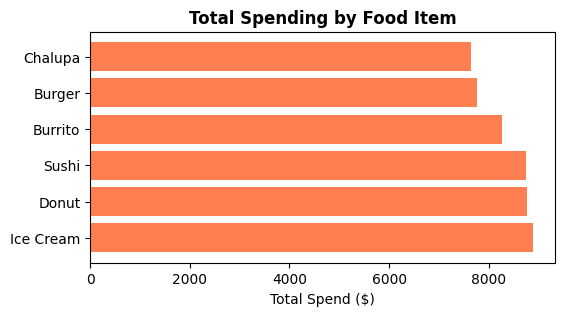

In [ ]:
plt.figure(figsize=(6,3))
plt.barh(item_total.index, item_total.values, color = "coral")
plt.title("Total Spending by Food Item", fontweight = "bold")
plt.xlabel("Total Spend ($)")